# ridgeline

In [1]:
import json
import os
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
def scanFile(data):
    types = ["positive", "negative", "both"]
    tiers = ["<= 25%", "<= 50%", "<= 75%", "<= 100%"]
    typeIndex = 0

    spotNames = []
    rawData = []
    normalizedData = []
    positives = []
    negatives = []

    for sample in data["samples"]:
        if not hasLowVariance(sample["data"]):
            if sample["type"][0] == "positive":
                positives.append(sample)
            else:
                negatives.append(sample)

    # searchForEpitopesTree(positives, searchForEpitopesArea(positives))
    posFlank = [36, 40]
    positives = selectionSort(positives, posFlank)
    positives = splitSetsIntoTiers(4, (2**16 - 1), positives)
    negatives = splitSetsIntoTiers(4, (2**16 - 1), negatives)

    positiveEpitopes = []
    negativeEpitopes = []

    #     for pos in positives:
    #         if pos:
    #             positiveEpitopes.append(searchForEpitopesArea(pos))

    #     for neg in negatives:
    #         if neg:
    #             negativeEpitopes.append(searchForEpitopesArea(neg))

    for counter, posSet in enumerate(positives):
        xAxis, yAxis = getHeatmapAxes(posSet)
        inputData = []
        for pos in posSet:
            iData = []
            for spot in pos["data"]:
                iData.append(float(spot["normalizedIntensity"]))
                # iData.append(float(spot["rawIntensity"]))
            inputData.append(iData.copy())
        printHeatmap("sortTest SYNI pos - " + str(counter), inputData, xAxis, yAxis)


#     print("Positive Epitopes: ")
#     for counter, pEpi in enumerate(positiveEpitopes):
#         print(tiers[counter])
#         for epi in pEpi:
#             print(epi)

#     print("Negative Epitopes: ")
#     for counter, nEpi in enumerate(negativeEpitopes):
#         print(tiers[counter])
#         for epi in nEpi:
#             print(epi)


#     rawDat = []
#     iNormDat = []
#     setNames = []

#     for sample in data["samples"]:
#         if sample["type"][0] == types[typeIndex]:
#             setNames.append(sample["name"])
#             rawDat.clear()
#             iNormDat.clear()
#             for spots in sample["data"]:
#                 rawDat.append(float(spots["rawIntensity"]))
#                 iNormDat.append(float(spots["normalizedIntensity"]))
#             rawData.append(rawDat.copy())
#             normalizedData.append(iNormDat.copy())

#     normalizedData, rawData, setNames = lowVarianceFilter(normalizedData, rawData, setNames)
#     posFlank = [137, 140]
#     threshold = 0
# B12 - B16 [36, 40]
#     setNames, rawData = selectionSort(rawData, setNames, posFlank, threshold)
#     rawDataT, setNamesT = splitIntoTiers(4,(2 ** 16 -1),rawData,setNames)
#     tierNames = ["<= 25","<= 50","<= 75", "<= 100"]
#     epitopeList = []
#     for count, trDat in enumerate(rawDataT):
#         epitopeList.append(searchForEpitopes(trDat))
#         print("Epitopes of tier " + tierNames[count])
#         for epi in epitopeList[count]:
#             print(epi)

#     #searchForEpitopes(rawDataT[2]+rawDataT[3])
#     #print(epitopeList[0])

#     #printHeatmap("KCNA2-fp", normalizeToMax(rawData), spotNames, setNames)
#     #printHeatmap("KCNA2-fp", normalizedData, spotNames, setNames)


#     #normalizedData, rawData, spotNames = deletePositions(36, 41, normalizedData, rawData, spotNames)

#     #plotData, plotNames = sortByEpitope(rawData, setNames)
#     #for counter, rDat in enumerate(rawDataT):
#         #printHeatmap(" test syn - "+str(counter), normalizeToMax(rDat), spotNames, setNamesT[counter])

In [3]:
def splitIntoTiers(nTiers, maxValue, rawData, setNames):
    rawDataT = []
    setNamesT = []
    for i in range(nTiers):
        rawDataT.append([])
        setNamesT.append([])

    tierStep = maxValue / nTiers

    for counter, dataSet in enumerate(rawData):
        maxPoint = 0
        for dataPoint in dataSet:
            if dataPoint > maxPoint:
                maxPoint = dataPoint

        for i in range(nTiers):
            if maxPoint <= tierStep * (i + 1):
                rawDataT[i].append(dataSet)
                setNamesT[i].append(setNames[counter])
                break

    for i, tierSet in reversed(list(enumerate(rawDataT))):
        if not tierSet:
            del rawDataT[i]

    #     for i, tierNames in reversed(list(enumerate(setNamesT))):
    #         print(tierNames)
    #         if not tierNames:
    #             del setNamesT[i]
    return rawDataT, setNamesT

In [4]:
def splitSetsIntoTiers(nTiers, maxValue, data):
    tData = []

    for i in range(nTiers):
        tData.append([])

    tierStep = maxValue / nTiers

    for counter, dataSet in enumerate(data):
        maxPoint = 0
        for dataPoint in dataSet["data"]:
            if float(dataPoint["rawIntensity"]) > maxPoint:
                maxPoint = float(dataPoint["rawIntensity"])

        for i in range(nTiers):
            if maxPoint <= tierStep * (i + 1):
                tData[i].append(dataSet)
                break

    return tData

In [5]:
def sortByEpitope(data, setNames):
    epitopes = searchForEpitopes(data)

    plotData = []
    plotNames = []

    for epi in epitopes:
        for dataSet in data:
            for count, spot in enumerate(data):
                print(spot)
                if count >= epi[0] and count <= epi[1]:
                    if spot >= 0.9:
                        plotData.append(DataSet)

In [6]:
def lowVarianceFilter(normalizedData, rawData, setNames):

    sD = 0
    stringency = 0.25

    noNegatives = []
    for data in rawData:
        noNegatives.append(data.copy())

    for dat in noNegatives:
        del dat[4]
        del dat[4]
        del dat[4]

    i = len(noNegatives) - 1
    for dataSet in reversed(noNegatives):
        avg = sum(dataSet) / len(dataSet)
        maximum = np.max(dataSet)

        if avg / maximum >= stringency:
            del normalizedData[i]
            del rawData[i]
            del setNames[i]
        i -= 1

    return normalizedData, rawData, setNames

In [7]:
def hasLowVariance(dataSet):
    stringency = 0.25

    avg = 0
    maximum = 0
    count = 0
    for spot in dataSet:
        count += 1
        avg += float(spot["rawIntensity"])
        if float(spot["rawIntensity"]) > maximum:
            maximum = float(spot["rawIntensity"])

    avg /= count
    if avg / maximum <= stringency:
        return False

    return True

In [8]:
def normalizeToMax(data):
    maxSignal = 0
    for dataSet in data:
        for dataPoint in dataSet:
            if dataPoint > maxSignal:
                maxSignal = dataPoint

    if maxSignal > 0:
        for dataSet in data:
            for counter, dataPoint in enumerate(dataSet):
                dataSet[counter] = dataPoint / maxSignal
    return data

In [9]:
def indexToPosition(index):
    return "" + chr(int(index / 24) + 65) + str(index % 24 + 1)

In [10]:
def positionToIndex(position):
    letter = (ord(position[0]) - 65) * 24
    number = int(position[1:]) - 1

    return letter + number

In [17]:
def makeJoyDivisionDiagram(dPath):
    sns.set_theme(style="white", rc={"axes.facecolor": (0, 0, 0, 0)})

    names = []
    dataSetsRaw = []
    dataSetsNormalized = []
    for sample in data["samples"]:
        names.append(sample["name"])
        dataSetRaw = []
        dataSetNormalized = []
        for spot in sample["data"]:
            dataSetRaw.append(float(spot["rawIntensity"]))
            dataSetNormalized.append(float(spot["normalizedIntensity"]))
        dataSetsRaw.append(dataSetRaw.copy())
        dataSetsNormalized.append(dataSetNormalized.copy())

    df = pd.DataFrame(dataSetsRaw)

    df = df.stack().reset_index()
    df.columns = ["idx", "x", "y"]

    sns.set_theme(
        rc={
            "axes.facecolor": (0, 0, 0, 0),
            "figure.facecolor": "#000000",
            "axes.grid": False,
        }
    )
    g = sns.FacetGrid(df, row="idx", aspect=50, height=1)
    # Draw the densities in a few steps
    g.map(sns.lineplot, "x", "y", clip_on=False, alpha=1, linewidth=1.5)
    g.map(plt.fill_between, "x", "y", color="#000000")  # Area under the curve
    g.map(sns.lineplot, "x", "y", clip_on=False, color="#ffffff", lw=4)  # line
    # Set the subplots to overlap
    g.fig.subplots_adjust(hspace=-0.75)
    g.set_titles("")
    g.set(yticks=[], xticks=[], ylabel="", xlabel="")
    g.despine(bottom=True, left=True)

    plt.show()
    g.savefig("C:/Users/KaiKr/Desktop/KCNA2Division - dpi100.png", dpi=100)
    g.savefig("C:/Users/KaiKr/Desktop/KCNA2Division - dpi150.png", dpi=150)
    g.savefig("C:/Users/KaiKr/Desktop/KCNA2Division - dpi200.png", dpi=200)

In [18]:
def makeRidgelineDiagram(dPath):
    sns.set_theme(style="white", rc={"axes.facecolor": (0, 0, 0, 0)})

    names = []
    dataSetsRaw = []
    dataSetsNormalized = []
    for sample in data["samples"]:
        names.append(sample["name"])
        dataSetRaw = []
        dataSetNormalized = []
        for spot in sample["data"]:
            dataSetRaw.append(float(spot["rawIntensity"]))
            dataSetNormalized.append(float(spot["normalizedIntensity"]))
        dataSetsRaw.append(dataSetRaw.copy())
        dataSetsNormalized.append(dataSetNormalized.copy())

    usedSet = dataSetsRaw
    dataAverages = []

    for uSet in usedSet:
        dataAverages.append(sum(uSet) / len(uSet))

    sortedNames = [names for _, names in sorted(zip(dataAverages, names), reverse=True)]
    sortedData = [
        names for _, names in sorted(zip(dataAverages, usedSet), reverse=True)
    ]
    df = pd.DataFrame(sortedData)

    palette = sns.color_palette("Set2", len(usedSet))
    df = df.stack().reset_index()
    df.columns = ["idx", "x", "y"]

    sns.set_theme(
        rc={
            "axes.facecolor": (0, 0, 0, 0),
            "figure.facecolor": "#FFFFFF",
            "axes.grid": False,
        }
    )

    g = sns.FacetGrid(df, row="idx", aspect=50, height=1, palette=palette)
    g.map_dataframe(sns.kdeplot, "x", "y", fill=True, alpha=1)
    # g.map(ax.fill_between, 'x', 'y', color= palette[count]) # Area under the curve
    g.map(sns.lineplot, "x", "y", clip_on=False, alpha=1, linewidth=1.5)

    g.map(sns.lineplot, "x", "y", clip_on=False, color="#000000", lw=4)  # line

    g.set_titles("")
    axes = g.fig.axes
    for count, ax in enumerate(axes):
        ax.set_title(sortedNames[count], loc="left", y=0, fontweight="bold", size=20)

    g.fig.subplots_adjust(hspace=-0.75)
    g.set_titles("")
    g.set(yticks=[], xticks=[], ylabel="", xlabel="")
    g.despine(bottom=True, left=True)

    plt.show()

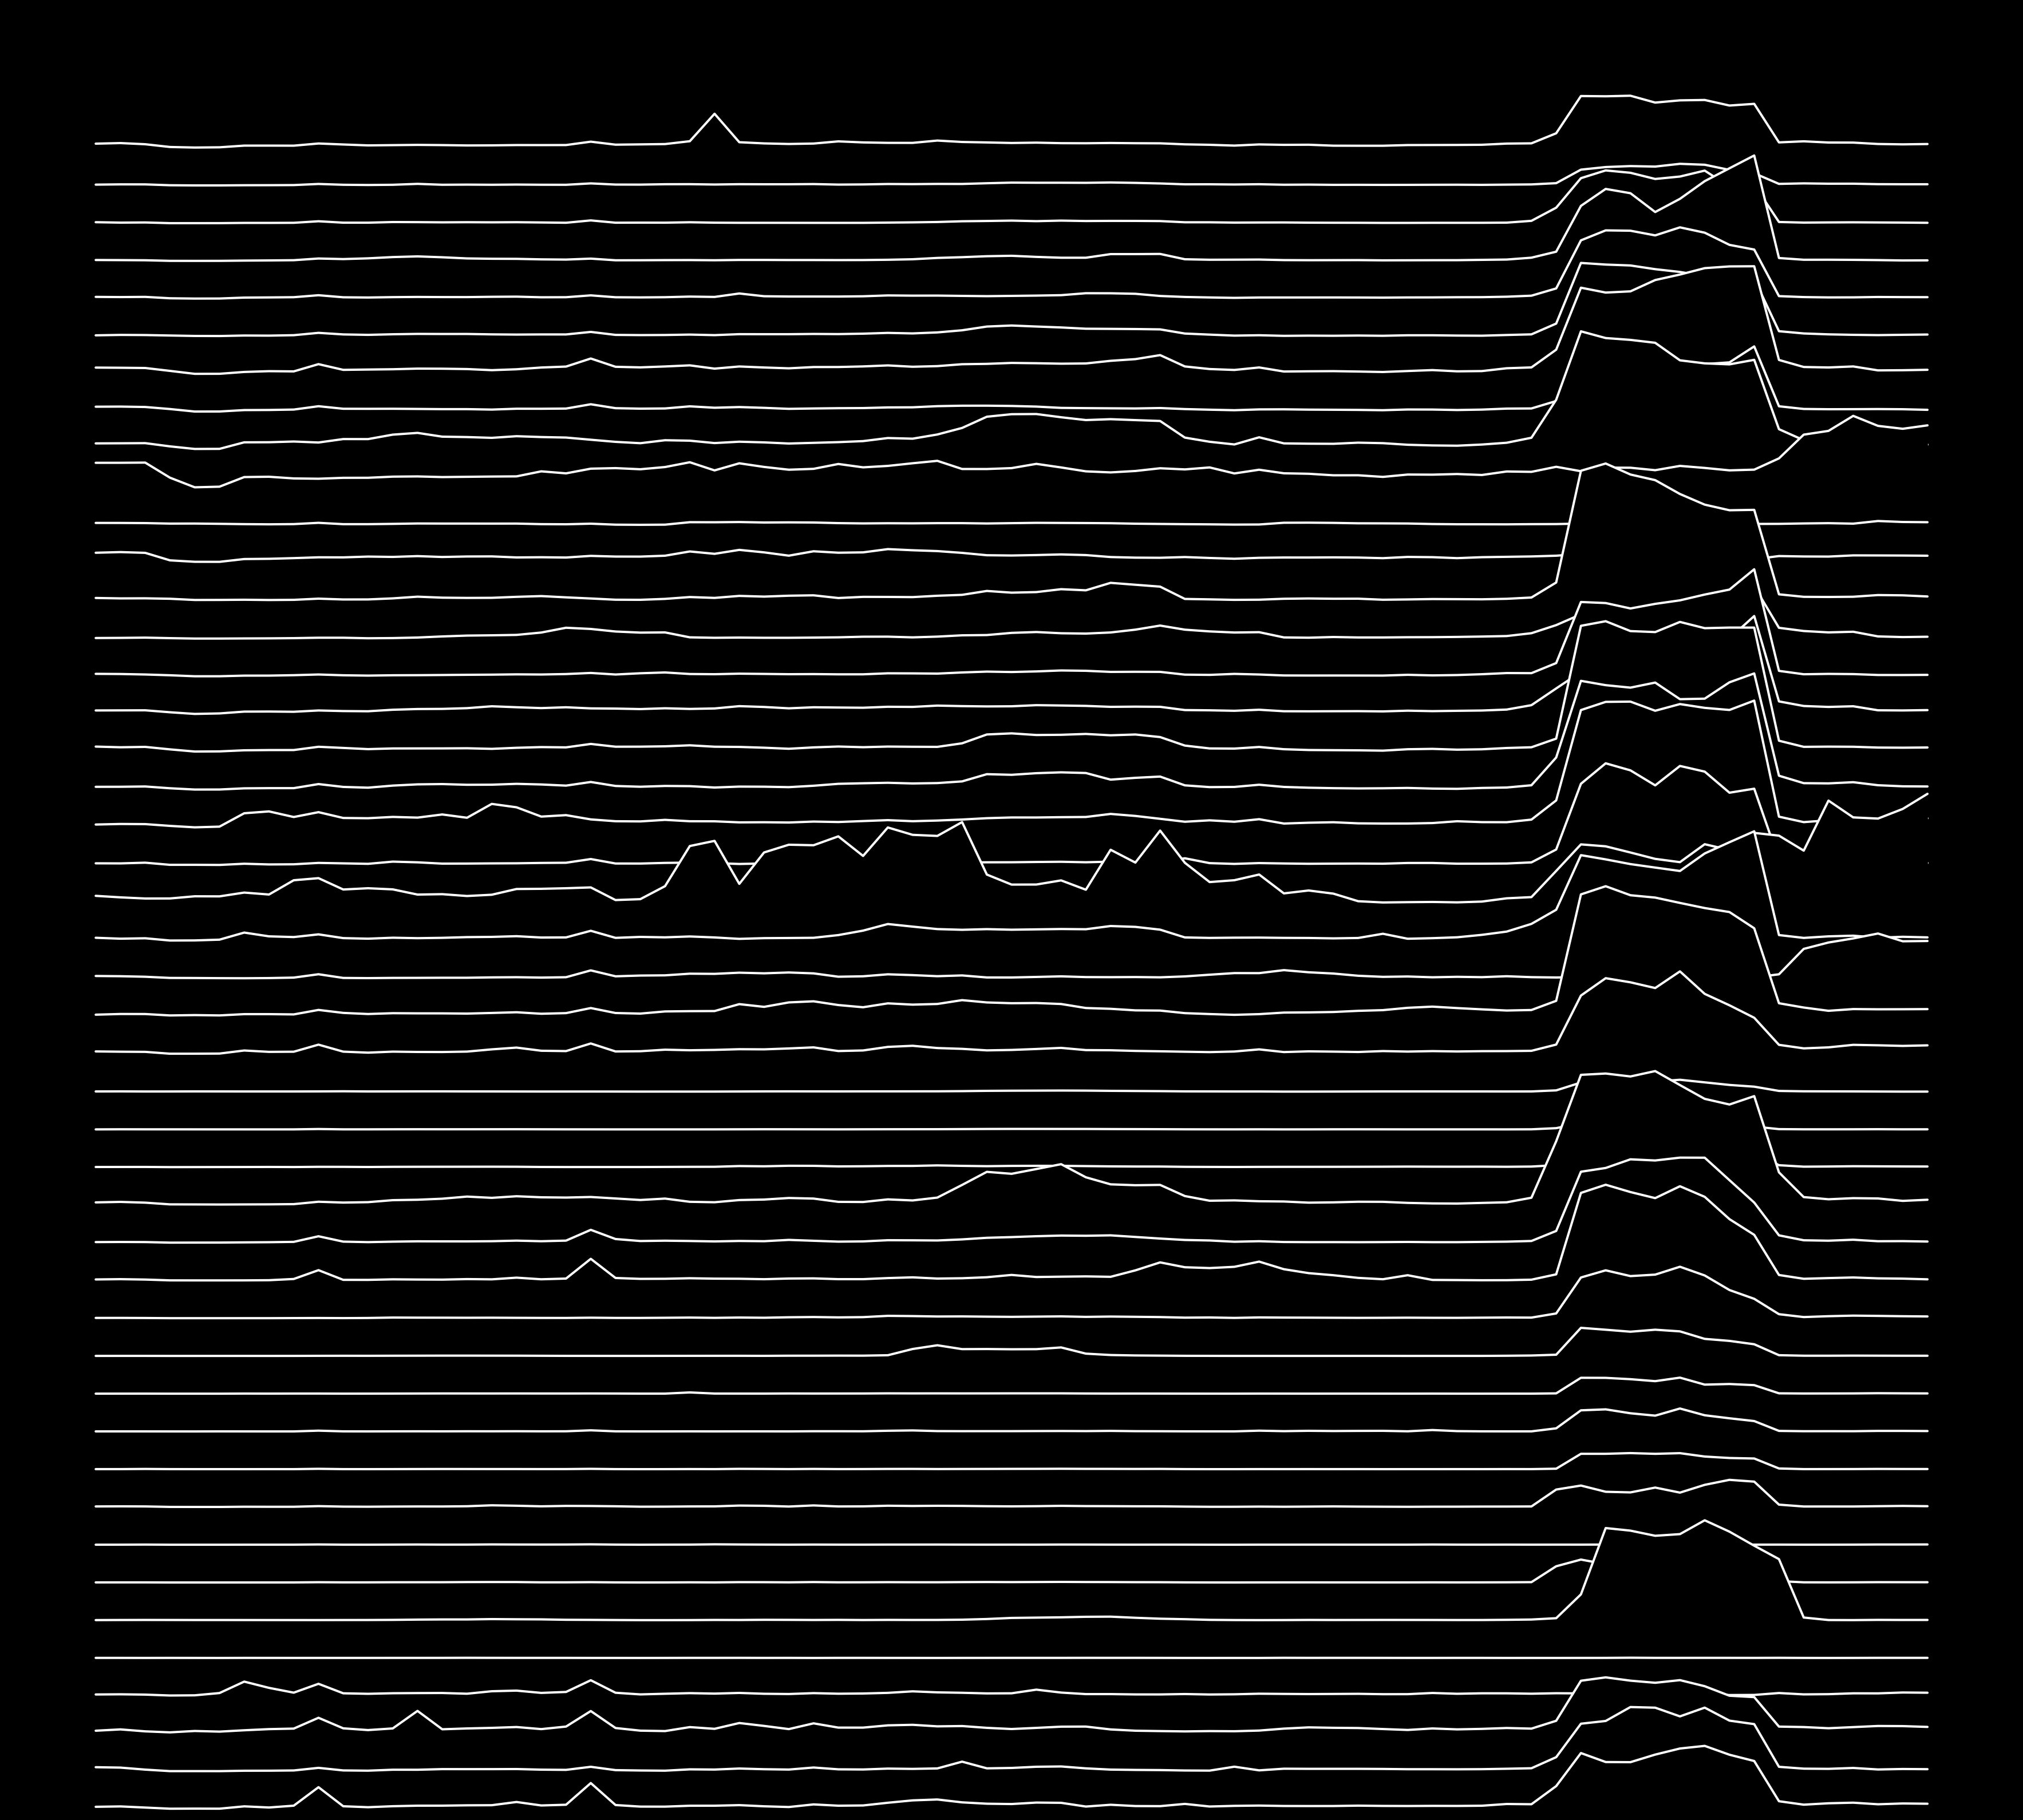

In [19]:
dPath = "C:/Users/KaiKr/Desktop/plots/"
with open(dPath + "KCNA2-HP.json") as file:
    data = json.load(file)

# scanFile(data)
# makeRidgelineDiagram(dPath)
makeJoyDivisionDiagram(dPath)